# Combine Observing Platforms: Satellite, Aircraft, and Radar

This example plans an aircraft underflight of a satellite's overpass of Phoenix, Arizona, and finds
where and when the satellite, the aircraft, and a ground-based weather radar observe the same places,
as for a field campaign that validates a satellite's observations of monsoon thunderstorms.

Satellites, aircraft, fixed surface platforms, and radar stations share one set of analysis functions:

* `collect_footprints` collects the footprints of the instruments of platforms of any kinds together,
  each named in the column of its kind (`satellite`, `aircraft`, `surface_platform`, or `radar_station`).
* `find_coincident_ground_track` pairs the overlapping footprints of different platforms, optionally
  only `between` two kinds (such as the underflights of a satellite by an aircraft).
* `collect_footprint_observations` samples the observations of points and regions from the footprints,
  which `find_coincident_observations` combines as it does for the observations of satellites.
* `collect_feature_observations` finds each platform's view of a feature (such as a storm) with its
  viewing geometry.

The satellite, the flight, and the storm are illustrative; the radar is the NEXRAD station KIWA
(Phoenix/Mesa), from the catalog's NEXRAD system, with the terrain mask of the `CollectRadarTrack` example.

In [1]:
import json
from datetime import datetime, timedelta, timezone

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pyproj import Geod
from shapely import force_3d
from shapely.geometry import Point, box
from skyfield.api import wgs84

from tatc.analysis import (
    collect_feature_observations,
    collect_footprint_observations,
    collect_footprints,
    collect_ground_track,
    dissolve_footprints,
    find_coincident_ground_track,
    find_coincident_observations,
)
from tatc.catalog import get_system
from tatc.generation import generate_points_uniform_spacing
from tatc.schemas import (
    Aircraft,
    PointedInstrument,
    Satellite,
    SunSynchronousOrbit,
    TerrainMask,
    Trajectory,
)
from tatc.utils import compute_along_track_field_of_view

GEOD = Geod(ellps="WGS84")
# the region of the campaign, in longitude/latitude
REGION = box(-113.5, 32.0, -110.0, 34.8)
# the time step (seconds) that each footprint represents
TIME_STEP = 10
# the observed level (meters above the WGS 84 ellipsoid), within a thunderstorm
LAYER = 3000
# colors of the platforms in maps
COLORS = {"satellite": "tab:blue", "aircraft": "tab:orange", "radar_station": "0.45"}


def make_map(title):
    """A map of the region, with state borders."""
    fig, ax = plt.subplots(figsize=(7, 6), subplot_kw={"projection": ccrs.PlateCarree()})
    ax.add_feature(cfeature.STATES, edgecolor="0.6", linewidth=0.6)
    ax.set_extent([-113.5, -110.0, 32.0, 34.8], crs=ccrs.PlateCarree())
    grid = ax.gridlines(draw_labels=True, linewidth=0.3, color="0.8")
    grid.top_labels = grid.right_labels = False
    ax.set_title(title)
    return fig, ax


def geodesic_area_km2(geometries):
    """The area (square kilometers) of geometries on the WGS 84 ellipsoid."""
    return sum(abs(GEOD.geometry_area_perimeter(g)[0]) for g in geometries) / 1e6

## Define the Satellite and Find an Overpass

The satellite carries a pushbroom imager with a 15 degree cross-track field of view (a swath of about
185 km), in a 705 km
sun-synchronous orbit crossing the equator at 13:30 local time. Its along-track field of view is
tailored to the time step (`compute_along_track_field_of_view`) so that consecutive footprints tile its
swath.

`collect_ground_track` with a mask finds the times the imager observes the region over four days, of
which the afternoon pass is the overpass to underfly. The time when the sub-satellite point is closest
to Phoenix, and the direction of the ground track there, come from the satellite's track
(`Satellite.get_track`).

In [2]:
START = datetime(2026, 8, 1, tzinfo=timezone.utc)
orbit = SunSynchronousOrbit(altitude=705e3, equator_crossing_time="13:30", epoch=START)
satellite = Satellite(
    name="Imager-1",
    orbit=orbit,
    instruments=[
        PointedInstrument(
            name="imager",
            cross_track_field_of_view=15,
            along_track_field_of_view=compute_along_track_field_of_view(
                705e3, TIME_STEP, orbit.get_inclination()
            ),
            field_of_regard=15,
            is_rectangular=True,
        )
    ],
)

# the passes over the region in four days (sampled each minute)
search = [START + timedelta(minutes=minutes) for minutes in range(4 * 24 * 60)]
passes = collect_ground_track(satellite, search, mask=REGION)
passes = passes[passes["valid_obs"]]
print("Passes over the region (UTC):")
print(passes["time"].dt.floor("min").to_string(index=False))

# the afternoon pass (UTC is 7 hours ahead of Arizona time)
afternoon = passes[passes["time"].dt.hour == 20]["time"].min()
window = [afternoon - timedelta(minutes=5) + timedelta(seconds=s) for s in range(600)]
subpoint = wgs84.subpoint_of(satellite.get_track(window))
latitude, longitude = subpoint.latitude.degrees, subpoint.longitude.degrees
PHOENIX = (-112.07, 33.45)
_, _, distance = GEOD.inv(
    longitude, latitude, np.full(len(window), PHOENIX[0]), np.full(len(window), PHOENIX[1])
)
closest = int(np.argmin(distance))
overpass = window[closest]
heading, _, _ = GEOD.inv(
    longitude[closest], latitude[closest], longitude[closest + 1], latitude[closest + 1]
)
print(f"\nOverpass at {overpass:%Y-%m-%d %H:%M:%S} UTC, {distance[closest] / 1e3:.1f} km from Phoenix")
print(f"Ground track heading {heading % 360:.1f} degrees")

Passes over the region (UTC):
2026-08-02 20:36:00+00:00
2026-08-02 20:37:00+00:00
2026-08-04 09:21:00+00:00

Overpass at 2026-08-02 20:36:31 UTC, 1.1 km from Phoenix
Ground track heading 347.0 degrees


## Plan the Underflight and Define the Radar

The aircraft flies a straight line along the satellite's ground track through Phoenix, at 200 m/s and
8 km altitude, for 20 minutes before and after the overpass, so that it passes under the overpass at the
same time. It carries a line scanner (a swept `PointedInstrument`) with a 60 degree cross-track field of
view, whose footprint over each time step is the strip it sweeps. `Trajectory.from_waypoints` flies the
line from its first waypoint to its last at the ground speed, with a state each second; without attitude, the
aircraft flies level along its track.

The NEXRAD station KIWA, built from the catalog's NEXRAD system (`get_system("nexrad")`) at its ground
elevation above the ellipsoid (its height above mean sea level plus the EGM2008 geoid height), observes the
storm layer with its terrain mask.

In [3]:
SPEED, ALTITUDE = 200.0, 8000.0  # m/s, meters above the ellipsoid
# the ends of the line, 20 minutes of flight behind and ahead of Phoenix
half_length = SPEED * 20 * 60
ends_longitude, ends_latitude, _ = GEOD.fwd(
    [PHOENIX[0]] * 2, [PHOENIX[1]] * 2, [heading + 180, heading], [half_length] * 2
)
aircraft = Aircraft(
    name="Survey aircraft",
    trajectory=Trajectory.from_waypoints(
        list(zip(ends_longitude, ends_latitude)),
        overpass - timedelta(minutes=20),
        speed=SPEED,
        altitude=ALTITUDE,
    ),
    instruments=[
        PointedInstrument(
            name="scanner",
            cross_track_field_of_view=60,
            along_track_field_of_view=1,
            field_of_regard=60,
            view_geometry="scan",
            is_swept=True,
        )
    ],
)

flight_longitude = aircraft.trajectory.longitude
flight_latitude = aircraft.trajectory.latitude

with open("../ground_systems/nexrad_phoenix_terrain_masks.json") as file:
    terrain_masks = json.load(file)
(radar,) = get_system("nexrad").build(members=["KIWA"])
radar = radar.model_copy(update={"terrain_mask": TerrainMask(**terrain_masks["KIWA"])})


## Collect the Footprints of Every Platform

`collect_footprints` collects the footprints of the three platforms at the same times, every 10 seconds
over the flight, at the storm layer, within the region. Each footprint names its platform in the column of
its kind. The radar does not move, so its footprint is the same at each time; with times, it samples the
same instants as the moving platforms (without times, a fixed platform's footprint is static).

     satellite: 7 valid footprints
      aircraft: 161 valid footprints
 radar_station: 241 valid footprints


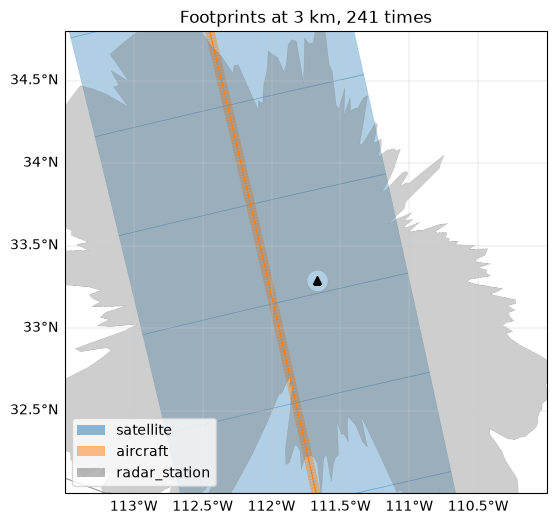

In [4]:
times = list(
    pd.date_range(
        overpass - timedelta(minutes=20),
        overpass + timedelta(minutes=20),
        freq=f"{TIME_STEP}s",
    ).to_pydatetime()
)
footprints = collect_footprints(
    [satellite, aircraft, radar], times, elevation=LAYER, mask=REGION
)
footprints = footprints[footprints["valid_obs"]].reset_index(drop=True)
for column in COLORS:
    print(f"{column:>14}: {footprints[column].notna().sum()} valid footprints")

fig, ax = make_map(f"Footprints at {LAYER / 1000:.0f} km, {len(times)} times")
for column, color in COLORS.items():
    subset = footprints[footprints[column].notna()]
    if column == "radar_station":
        subset = subset.iloc[:1]  # the same at every time
    subset.plot(ax=ax, facecolor=color, edgecolor=color, alpha=0.35, linewidth=0.3)
ax.plot(flight_longitude, flight_latitude, color=COLORS["aircraft"], linewidth=0.8)
ax.plot(radar.longitude, radar.latitude, "k^")
ax.legend(
    handles=[Patch(facecolor=color, alpha=0.5, label=column) for column, color in COLORS.items()],
    loc="lower left",
)
plt.show()

## Find the Underflights

`find_coincident_ground_track` pairs the overlapping footprints of different platforms whose times differ by
at most `max_time_difference`. With `between=("satellite", "aircraft")`, it keeps only the underflights:
the pairs of a satellite footprint and an aircraft footprint, with the satellite's first (`satellite_1`,
`time_1`) and the aircraft's second, so that `time_difference` (`time_2` less `time_1`) is negative where
the aircraft passes before the satellite. Without `between`, it would also pair the radar's coverage with
each of the other platforms: the radar's footprint is the same at each time, so each footprint of another
platform pairs with its copy nearest in time.

Dissolving the pairs (`dissolve_footprints`) gives the area that both observe within 10 minutes (of the pairs
whose footprints are both valid observations, `valid_obs`), here colored by the time difference.

129 pairs of satellite and aircraft footprints
                   time_1 satellite_1                    time_2      aircraft_2  minutes
2026-08-02 20:36:11+00:00    Imager-1 2026-08-02 20:26:11+00:00 Survey aircraft    -10.0
2026-08-02 20:36:21+00:00    Imager-1 2026-08-02 20:30:11+00:00 Survey aircraft     -6.2
2026-08-02 20:36:31+00:00    Imager-1 2026-08-02 20:34:11+00:00 Survey aircraft     -2.3
2026-08-02 20:36:31+00:00    Imager-1 2026-08-02 20:38:21+00:00 Survey aircraft      1.8
2026-08-02 20:36:41+00:00    Imager-1 2026-08-02 20:42:21+00:00 Survey aircraft      5.7
2026-08-02 20:36:51+00:00    Imager-1 2026-08-02 20:46:21+00:00 Survey aircraft      9.5

Area observed by both within 10 minutes: 1,441 km2


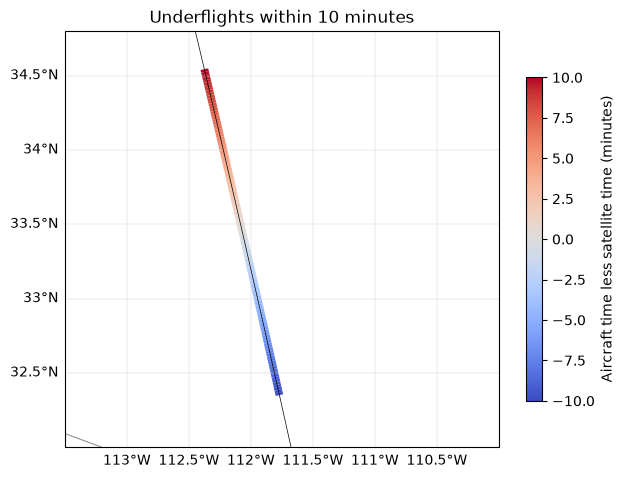

In [5]:
underflights = find_coincident_ground_track(
    footprints, timedelta(minutes=10), between=("satellite", "aircraft")
)
print(f"{len(underflights)} pairs of satellite and aircraft footprints")
minutes = underflights["time_difference"].dt.total_seconds() / 60
print(
    underflights[["time_1", "satellite_1", "time_2", "aircraft_2"]]
    .assign(minutes=minutes.round(1))
    .iloc[:: max(1, len(underflights) // 5)]
    .to_string(index=False)
)
common = dissolve_footprints(underflights)
print(f"\nArea observed by both within 10 minutes: {geodesic_area_km2(common.geometry):,.0f} km2")

fig, ax = make_map("Underflights within 10 minutes")
underflights.assign(minutes=minutes).plot(
    column="minutes", cmap="coolwarm", vmin=-10, vmax=10, ax=ax, legend=True,
    legend_kwds={"label": "Aircraft time less satellite time (minutes)", "shrink": 0.7},
)
ax.plot(flight_longitude, flight_latitude, color="k", linewidth=0.5)
plt.show()

## Find Points Observed by All Three Platforms

`collect_footprint_observations` samples the observations of points (here, a grid with 5 km spacing) from
the footprints (at the observed level, as the footprints are, which their z-coordinate gives; a point at
another elevation warns): each observation spans the times of consecutive footprints of a platform's instrument that
contain a point. The radar observes a point at every time within its coverage, the aircraft for the few
seconds its scanner sweeps over it, and the satellite at the instant of one footprint. A radar station has
no instruments, so its observations have no `instrument`. Given the platforms of the footprints
(`platforms`), each observation also has the elevation and azimuth angles of its platform seen from
the point at its epoch (`platform_alt` and `platform_az`).

The observations have the columns of `collect_observations`, so `find_coincident_observations` finds the
points that all three platforms observe within 10 minutes (`min_platforms=3`), naming the contributors of
each kind in its column. Each observation is widened by half the maximum time difference (5 minutes)
before and after, and a coincident period spans the time that the widened observations of all three
overlap.

     satellite: observes 2804 of 4836 points
      aircraft: observes 86 of 4836 points
 radar_station: observes 3456 of 4836 points

68 points observed by all three within 10 minutes
satellite        aircraft radar_station      instrument                     start                       end
 Imager-1 Survey aircraft          KIWA imager, scanner 2026-08-02 20:31:11+00:00 2026-08-02 20:31:41+00:00
 Imager-1 Survey aircraft          KIWA imager, scanner 2026-08-02 20:31:11+00:00 2026-08-02 20:31:51+00:00
 Imager-1 Survey aircraft          KIWA imager, scanner 2026-08-02 20:31:11+00:00 2026-08-02 20:32:11+00:00
 Imager-1 Survey aircraft          KIWA imager, scanner 2026-08-02 20:31:11+00:00 2026-08-02 20:32:41+00:00
 Imager-1 Survey aircraft          KIWA imager, scanner 2026-08-02 20:31:11+00:00 2026-08-02 20:31:21+00:00


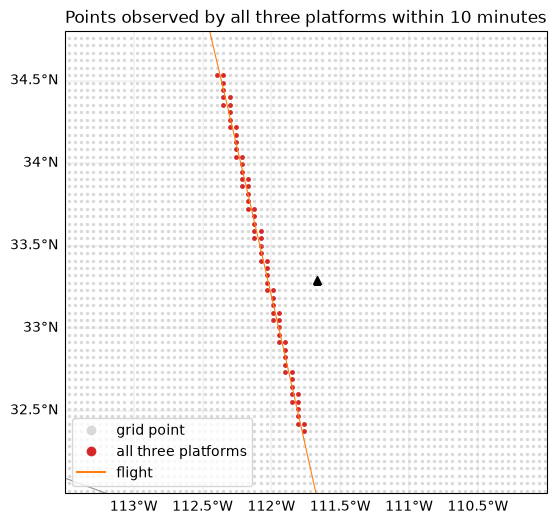

In [6]:
points = generate_points_uniform_spacing(5e3, mask=REGION)
# at the observed level, as the footprints are
points["geometry"] = gpd.points_from_xy(
    points.geometry.x, points.geometry.y, np.full(len(points), LAYER), crs=points.crs
)
observations = collect_footprint_observations(
    points, footprints, platforms=[satellite, aircraft, radar]
)
for column in COLORS:
    observed = observations[observations[column].notna()]
    print(f"{column:>14}: observes {observed['target_hash'].nunique()} of {len(points)} points")

coincident = find_coincident_observations(
    observations, min_platforms=3, max_time_difference=timedelta(minutes=10)
)
print(f"\n{coincident['target_hash'].nunique()} points observed by all three within 10 minutes")
print(
    coincident[["satellite", "aircraft", "radar_station", "instrument", "start", "end"]]
    .head()
    .to_string(index=False)
)

fig, ax = make_map("Points observed by all three platforms within 10 minutes")
points.plot(ax=ax, color="0.85", markersize=2)
coincident.plot(ax=ax, color="tab:red", markersize=6)
ax.plot(flight_longitude, flight_latitude, color=COLORS["aircraft"], linewidth=0.8)
ax.plot(radar.longitude, radar.latitude, "k^")
ax.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color="0.85", label="grid point"),
        Line2D([], [], marker="o", linestyle="", color="tab:red", label="all three platforms"),
        Line2D([], [], color=COLORS["aircraft"], label="flight"),
    ],
    loc="lower left",
)
plt.show()

## Observe a Region

`collect_footprint_observations` also samples the observations of regions (polygons), here the Phoenix
metropolitan area at the observed level: each observation spans a run of consecutive footprints of a
platform's instrument that overlap the region, and its geometry is the swath, the part of the region that
the run covers. Its `target_hash` is that of `collect_region_observations`, so the observations sampled
from footprints combine with those that a satellite's orbit gives for the same region.

The satellite's swath crosses nearly all of the region in two footprints (10 seconds), the aircraft's
scanner sweeps a strip of it for several minutes, and the radar covers most of it (all but its cone of
silence) at every time, in one observation that spans the flight.

       platform    start      end  swath (% of region)
           KIWA 20:16:31 20:56:31                 97.0
Survey aircraft 20:34:31 20:39:31                  7.5
       Imager-1 20:36:31 20:36:41                 99.9


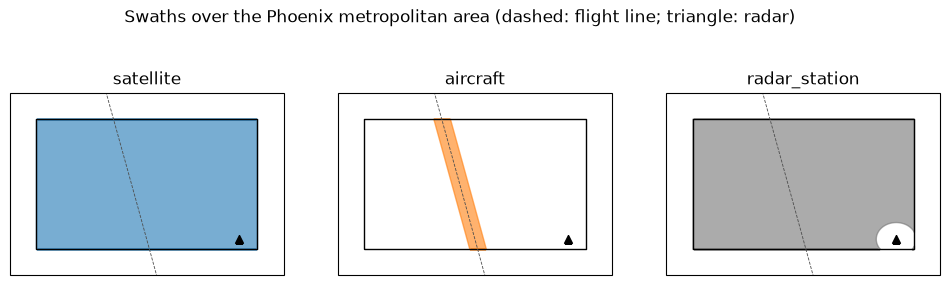

In [7]:
# the Phoenix metropolitan area, at the observed level
metro = force_3d(box(-112.45, 33.25, -111.6, 33.75), LAYER)
visits = collect_footprint_observations(metro, footprints)
visits["platform"] = (
    visits["satellite"].fillna(visits["aircraft"]).fillna(visits["radar_station"])
)
metro_area = geodesic_area_km2([metro])
print(
    pd.DataFrame(
        {
            "platform": visits["platform"],
            "start": visits["start"].dt.strftime("%H:%M:%S"),
            "end": visits["end"].dt.strftime("%H:%M:%S"),
            "swath (% of region)": [
                100 * geodesic_area_km2([swath]) / metro_area for swath in visits.geometry
            ],
        }
    )
    .round(1)
    .to_string(index=False)
)

# the swaths of each platform, near the region
west, south, east, north = metro.bounds
fig, axes = plt.subplots(
    1, 3, figsize=(12, 3.6), subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, (column, color) in zip(axes, COLORS.items()):
    ax.set_extent([west - 0.1, east + 0.1, south - 0.1, north + 0.1], crs=ccrs.PlateCarree())
    visits[visits[column].notna()].plot(ax=ax, facecolor=color, edgecolor=color, alpha=0.6)
    gpd.GeoSeries([metro]).boundary.plot(ax=ax, color="k", linewidth=1)
    ax.plot(flight_longitude, flight_latitude, color="0.3", linewidth=0.6, linestyle="--")
    ax.plot(radar.longitude, radar.latitude, "k^")
    ax.set_title(column)
fig.suptitle("Swaths over the Phoenix metropolitan area (dashed: flight line; triangle: radar)")
plt.show()

## Compare the Viewing Angles

The angles of the observations of points (with `platforms`, as above) compare the platforms' views: the
satellite views each point near nadir, the aircraft's scanner up to 30 degrees from nadir at a short range,
and the radar from below the observed level, at a negative elevation angle.

In [8]:
observations["platform"] = (
    observations["satellite"]
    .fillna(observations["aircraft"])
    .fillna(observations["radar_station"])
)
(
    observations.groupby("platform")["platform_alt"]
    .describe()[["count", "min", "50%", "max"]]
    .rename(columns={"50%": "median"})
    .round(1)
)

,count,min,median,max
platform,,,,
Imager-1,2804.0,81.1,85.4,90.0
KIWA,3456.0,-18.8,-1.8,-1.6
Survey aircraft,86.0,60.3,73.5,86.4


## Observe a Storm Cell

`collect_feature_observations` finds each platform's view of a feature that exists for a period, such as a
thunderstorm cell of a nature run: the part of it inside the platform's valid footprints, at the time of the
footprint that covers most of it, with the viewing geometry from the centroid of the viewed part. The
viewing geometry has the same columns for every kind of platform (`platform_alt`, `platform_az`,
`platform_range`, and `platform_height`), as the angles of footprints do.

Here, a storm cell about 25 km across lies under the flight line, north of Phoenix and about 50 km from
the radar, during the flight. The elevation angle is that of the platform seen from the storm, so it is
negative for the radar, below the observed level. The radar's coverage does not change, so it views the
cell equally at every time, of which the time reported is one.

In [9]:
storm = gpd.GeoDataFrame(
    {
        "start": [pd.Timestamp(overpass - timedelta(minutes=30))],
        "end": [pd.Timestamp(overpass + timedelta(minutes=30))],
    },
    geometry=[Point(-112.1, 33.6).buffer(0.12)],
    crs="EPSG:4326",
)
looks = collect_feature_observations(storm, [satellite, aircraft, radar], times, elevation=LAYER)
geometry = pd.DataFrame(
    {
        "platform": looks["satellite"].fillna(looks["aircraft"]).fillna(looks["radar_station"]),
        "time": looks["time"].dt.strftime("%H:%M:%S"),
        "viewed (%)": 100 * looks["viewed_fraction"],
        "elevation angle (deg)": looks["platform_alt"],
        "slant range (km)": looks["platform_range"] / 1e3,
    }
)
geometry.round(1)

,platform,time,viewed (%),elevation angle (deg),slant range (km)
0,KIWA,20:16:31,100.0,-3.1,52.9
1,Imager-1,20:36:31,100.0,88.5,699.5
2,Survey aircraft,20:38:51,32.2,24.5,12.0


The satellite views the whole cell from above at once; the aircraft's narrow swath views a strip of it from
5 km above the layer; and the radar views it at a low angle from below the layer, over the whole period. The same functions apply to fixed surface platforms (`SurfacePlatform`, such as
towers with cameras), whose footprints `collect_footprints` collects with the others.